In [1]:
%pip install plotly
%pip install openpyxl
%pip install seaborn
%pip install matplotlib
%pip install pandas
%pip install numpy
%pip install nbformat

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


... (4 outputs left out)

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

df = pd.read_csv("../data/Processed_UICLibraryData.csv")

In [3]:
df["occupancy_index"] = df.groupby("floor")["occupancy_count"].transform(
    lambda x: x / x.iloc[0] * 100
)

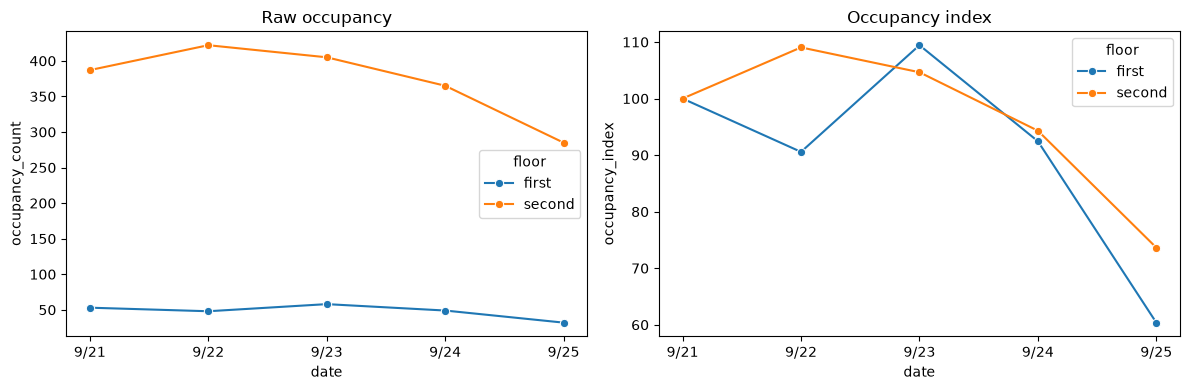

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(
    data=df,
    x="date",
    y="occupancy_count",
    hue="floor",
    marker="o",
    ax=axes[0]
)

sns.lineplot(
    data=df,
    x="date",
    y="occupancy_index",
    hue="floor",
    marker="o",
    ax=axes[1]
)

axes[0].set_title("Raw occupancy")
axes[1].set_title("Occupancy index")

plt.tight_layout()
plt.show()

In [5]:
import plotly.graph_objects as go

fig = go.Figure()

for floor in ["first", "second"]:
    d = df[df["floor"] == floor]
    fig.add_trace(go.Scatter(
        x=d["date"], y=d["occupancy_count"],
        mode="lines+markers", name=floor
    ))

for floor in ["first", "second"]:
    d = df[df["floor"] == floor]
    fig.add_trace(go.Scatter(
        x=d["date"], y=d["occupancy_index"],
        mode="lines+markers", name=floor,
        visible=False
    ))

fig.update_layout(
    title="Raw occupancy",
    yaxis_title="occupancy_count",
    updatemenus=[dict(
        buttons=[
            dict(
                label="Raw occupancy",
                method="update",
                args=[
                    {"visible": [True, True, False, False]},
                    {"title": "Raw occupancy",
                     "yaxis": {"title": "occupancy_count"}}
                ]
            ),
            dict(
                label="Occupancy index",
                method="update",
                args=[
                    {"visible": [False, False, True, True]},
                    {"title": "Occupancy index",
                     "yaxis": {"title": "Occupancy index (Monday = 100)"}}
                ]
            )
        ]
    )]
)

fig.show()